# GridWorld — Enhancement 2: masked momentum

Compare momentum strengths $\lambda\in\{0.5,1,2\}$ with the baseline ($\lambda=0$).
Every run uses the baseline's tuned stepsize $\eta$, observation budget, and seeds,
all read from `results/gridworld_baseline.npz`. The baseline curve is loaded from
that file and is not rerun.

Only pairs required in both consecutive iterations contribute to momentum:

$$B_k(s,a)=\mathbf 1\{(s,a)\in\mathcal E_k\cap\mathcal E_{k-1}\},$$
$$\Delta_k=B_k\odot(\widehat Q_k-\widehat Q_{k-1}),\qquad
M_k=\widehat Q_k+\lambda\Delta_k.$$

At $k=0$, set $\Delta_0=0$. Required pairs satisfy
$\pi_k(a\mid s)\ge0.025$; all other Q entries retain the fallback value 10.
Fallback transitions therefore do not contribute to $\Delta_k$.

One policy-update function is used for all lambdas. Setting $\lambda=0$
gives the baseline update. Values are recorded from the original $\widehat Q_k$
and the pre-update policy $\pi_k$, not from $M_k$.

The comparison uses the exact value $V^{\pi_k}(s_0)$ of every learned policy
(Bellman evaluation, never used for learning), averaged over five seeds with 95%
confidence intervals. Section 12 repeats the experiment with exact Q values, to
separate the effect of momentum from the effect of sampling noise.

**How to run:** run `gridworld_baseline.ipynb` first, keep `gridworld_results.py`
in the same folder, then run the cells in order (about one hour).
Dependencies: **NumPy, pandas, Matplotlib**.

In [1]:
# %pip install numpy pandas matplotlib   # Uncomment if a package is missing.

## 1. Settings and a fixed map

Rows and columns start at zero; state `s = 10 * row + column`. State 0 is the
origin and reporting state. `H` means hazard, `G` goal, `O` origin, and `.`
ordinary cell. Arrays use **[state, action]**.

We use `gamma = 0.9`. The stepsize `ETA` and the observation budget
`SAMPLE_BUDGET` are the baseline's, loaded from its results file.
The momentum strengths are `LAMBDAS = (0.5, 1.0, 2.0)`. Set
`HISTORY_LENGTH = 100` for the minimum history required before stopping.
Each Q estimate uses all costs from its first visit to the common batch end. Required pairs satisfy
`policy[s, a] >= PI_THRESHOLD`, where
`PI_THRESHOLD = (1 - GAMMA) / N_ACTIONS = 0.025`.
The number of observations per iteration is determined by collection,
not by a fixed batch length or a time limit.

In [2]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FuncFormatter, NullFormatter

from gridworld_results import (
    SEEDS, BASELINE_COLOR, SERIES_COLORS, INK, MUTED, optimal_values, save_runs, load_runs,
    sample_grid, on_grid, mean_ci, format_mean_ci, apply_plot_style, plot_band, save_figure,
)

# The baseline supplies the tuned stepsize, the budget, and the lambda = 0 curve.
baseline_runs, baseline_settings = load_runs("gridworld_baseline")

# Learning settings. Every lambda uses these same values, taken from the baseline.
GAMMA = 0.9               # Discount on future costs.
ETA = float(baseline_settings["eta"])                   # Tuned in the baseline notebook.
SAMPLE_BUDGET = int(baseline_settings["sample_budget"])  # Observations in one run.
HISTORY_LENGTH = 100       # Minimum cost terms after a required pair's first visit.
LAMBDAS = (0.5, 1.0, 2.0)  # Momentum strengths; lambda = 0 is the loaded baseline.

# Environment settings: intended direction, reset probability, and state costs.
P_INTENDED = 0.8
Q_MOVE = 0.2              # At a goal/hazard: move with .2, return to origin with .8.
C_GOAL, C_REGULAR, C_HAZARD = 0.0, 0.2, 1.0

# O: origin, G: goal, H: hazard, and .: ordinary cell.
LAYOUT = (
    "O........G",
    "..H....H..",
    ".....H....",
    ".H......H.",
    "..........",
    "...H.G....",
    "......H...",
    ".H........",
    "....H...H.",
    ".........G",
)
# The table uses state IDs 0,...,99, with state = row * N_COLS + column.
grid = np.array([list(row) for row in LAYOUT])
N_ROWS, N_COLS = grid.shape
N_STATES, N_ACTIONS = grid.size, 4
# This threshold selects pairs that need sampled Q estimates, not actions to sample.
PI_THRESHOLD = (1 - GAMMA) / N_ACTIONS
# Convert the marked grid cells into state IDs for quick membership checks.
GOALS = set(np.flatnonzero(grid.ravel() == "G"))
HAZARDS = set(np.flatnonzero(grid.ravel() == "H"))
ORIGIN = int(np.flatnonzero(grid.ravel() == "O")[0])
REPORT_STATE = ORIGIN

# Action index and movement direction use this same order everywhere.
ACTION_NAMES = ("up", "right", "down", "left")
DIRECTIONS = ((-1, 0), (0, 1), (1, 0), (0, -1))

# Check that the fixed map and costs match the intended problem.
assert grid.shape == (10, 10)
assert len(GOALS) == 3 and len(HAZARDS) == 10
assert np.count_nonzero(grid == "O") == 1
assert ORIGIN not in GOALS | HAZARDS and GOALS.isdisjoint(HAZARDS)

assert (
    0 <= min(C_GOAL, C_REGULAR, C_HAZARD)
    <= max(C_GOAL, C_REGULAR, C_HAZARD) <= 1
)
assert float(baseline_settings["gamma"]) == GAMMA

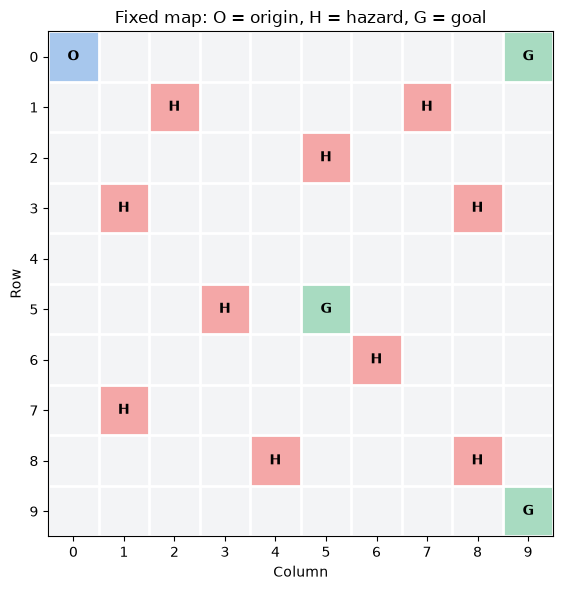

In [3]:
# The colors and letters show the fixed environment, not a learned policy.
colors = {".": 0, "H": 1, "G": 2, "O": 3}
map_colors = np.array([[colors[cell] for cell in row] for row in grid])
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(
    map_colors,
    cmap=ListedColormap(["#f3f4f6", "#f4a7a7", "#a8dbc1", "#a7c7ed"]),
    vmin=0,
    vmax=3,
)
# Label only special cells; ordinary cells keep their background color.
for (row, col), cell in np.ndenumerate(grid):
    if cell != ".":
        ax.text(col, row, cell, ha="center", va="center", fontweight="bold")
ax.set(xticks=range(N_COLS), yticks=range(N_ROWS), xlabel="Column", ylabel="Row",
       title="Fixed map: O = origin, H = hazard, G = goal")
# Minor ticks put the grid lines on cell boundaries.
ax.set_xticks(np.arange(-0.5, N_COLS, 1), minor=True)
ax.set_yticks(np.arange(-0.5, N_ROWS, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="minor", bottom=False, left=False)
plt.tight_layout()
plt.show()

## 2. Environment: give an action, receive (cost, next state)

The environment owns its current state. Ordinary motion follows the intended
direction with probability 0.8 and **each of the other three directions** with
probability $0.2/3$. An attempted move through a wall stays in the same cell.

The cost is charged at the **current state before moving**: goal 0, hazard 1,
ordinary cell (including origin) 0.2. From a goal or hazard, the next step
returns to the origin with probability 0.8; with probability 0.2 it follows
ordinary movement. Thus, entering a hazard does not immediately charge the
hazard cost; the next observation does. Goals and hazards are **not terminal**.

We sample these rules directly; the learner never receives a transition matrix.

In [4]:
def move(state, direction):
    """Attempt one move; clipping handles the grid walls."""
    # Translate the integer state into grid coordinates, then back after moving.
    row, col = divmod(state, N_COLS)
    dr, dc = DIRECTIONS[direction]
    row = min(max(row + dr, 0), N_ROWS - 1)
    col = min(max(col + dc, 0), N_COLS - 1)
    return row * N_COLS + col


class GridWorld:
    def __init__(self):
        self.state = ORIGIN  # Reset only when starting a new run.
        # Each row corresponds to an action; columns are actual movement directions.
        self.move_probs = np.full((N_ACTIONS, N_ACTIONS), (1 - P_INTENDED) / 3)
        np.fill_diagonal(self.move_probs, P_INTENDED)

    def step(self, action, rng):
        """Charge the current-state cost, then sample the next state."""
        state = self.state
        # Cost belongs to the current state, before this transition takes place.
        cost = (
            C_GOAL if state in GOALS
            else C_HAZARD if state in HAZARDS
            else C_REGULAR
        )
        # At a goal or hazard, first decide whether to return to the origin.
        if state in GOALS | HAZARDS and rng.random() < 1 - Q_MOVE:
            next_state = ORIGIN
        else:
            # Otherwise sample the actual direction, which may differ from the action.
            direction = rng.choice(N_ACTIONS, p=self.move_probs[action])
            next_state = move(state, direction)
        # Keep this state for the next interaction, including across batch boundaries.
        self.state = next_state
        return cost, next_state

## 3. Collect dynamically under a frozen policy

Let $\mathcal E_k=\{(s,a):\pi_k(a\mid s)\ge\underline\pi\}$ and let
$\tau_k(s,a)$ be the first visit index within the current batch, starting at 0.
Collect until

$$n_k=\max_{(s,a)\in\mathcal E_k}\tau_k(s,a)+T,\qquad T=100.$$

Thus every required pair has at least 100 consecutive costs available from
its first visit, and the last required pair discovered has exactly 100.
**The cost at the first visit is term 1: collect 99 more costs after it.**
This does not require 100 visits to that pair. Each required pair uses
**all costs from its first visit through the common batch end**.
Earlier pairs therefore use more than 100 terms; the last required
pair discovered uses exactly 100. Nothing is cut off at term 100.

The policy is frozen throughout collection. The environment continues from
the previous batch's endpoint. All pairs and their first visits are tracked
afresh for each policy. Below-threshold pairs do not delay collection.
There is no observation cap or timeout; rare required pairs can make a batch long.

In [5]:
def required_pair_mask(policy, pi_threshold):
    """Validate a policy and identify the homework's required pairs."""
    # Rows are states and columns are actions; each row must be a probability vector.
    policy = np.asarray(policy, dtype=float)
    if policy.ndim != 2 or min(policy.shape) == 0:
        raise ValueError("policy must be a nonempty [state, action] array")
    if not np.isfinite(policy).all() or (policy < 0).any():
        raise ValueError("policy probabilities must be finite and nonnegative")
    if not np.allclose(policy.sum(axis=1), 1.0, rtol=0, atol=1e-12):
        raise ValueError("each policy row must sum to one")
    if not 0 < pi_threshold <= 1 / policy.shape[1]:
        raise ValueError("pi_threshold must be in (0, 1 / number_of_actions]")
    # Equality is included: an action exactly at the threshold is required.
    return policy >= pi_threshold


def collect_batch(env, policy, history_length, rng, pi_threshold=PI_THRESHOLD):
    """Stop as soon as the last required first visit has history_length costs."""
    if not isinstance(history_length, (int, np.integer)) or history_length < 1:
        raise ValueError("history_length must be a positive integer")
    # Hold this policy and its required set fixed for the entire batch.
    required = required_pair_mask(policy, pi_threshold)
    # -1 means the pair has not appeared in this batch; missing counts required pairs.
    first_visits = np.full(policy.shape, -1, dtype=int)
    missing = int(required.sum())
    # Begin at the environment's current state, not a fresh reset to the origin.
    states, actions, costs = [int(env.state)], [], []
    stop_after = None

    # First discover every required pair, then finish its minimum cost history.
    while stop_after is None or len(costs) < stop_after:
        t = len(costs)
        state = states[-1]
        # Sample from the full policy; the threshold does not change action probabilities.
        action = int(rng.choice(policy.shape[1], p=policy[state]))
        cost, next_state = env.step(action, rng)
        actions.append(action)
        costs.append(cost)
        states.append(int(next_state))

        # Repeated visits do not restart or extend the first-visit history.
        if first_visits[state, action] == -1:
            first_visits[state, action] = t
            if required[state, action]:
                missing -= 1
                if missing == 0:
                    # C_t is already collected: it is the first of T terms.
                    stop_after = t + history_length

    # n interactions produce n actions/costs and n+1 states, including the endpoint.
    return (
        np.asarray(states, dtype=int),
        np.asarray(actions, dtype=int),
        np.asarray(costs, dtype=float),
    )

## 4. Full-history first-visit TOMC estimator

Once collection ends at $n_k$, use each required pair's entire first-visit suffix:

$$\widehat Q_k(s,a)=
\begin{cases}
\displaystyle\sum_{t=\tau_k(s,a)}^{n_k-1}
\gamma^{t-\tau_k(s,a)}C_t,
&\pi_k(a\mid s)\ge\underline\pi,\\[2mm]
\displaystyle\frac{1}{1-\gamma},
&\pi_k(a\mid s)<\underline\pi.
\end{cases}$$

The number of terms is $n_k-\tau_k(s,a)\ge100$ for each required pair.
The immediate cost has weight $\gamma^0=1$. Below-threshold pairs receive
10 when $\gamma=0.9$, even if observed. Repeated visits are counted for
diagnostics; we use one full first-visit return, without averaging or selecting
the smallest observed return.

Compute all suffix returns backward using $G_{n_k}=0$ and
$G_t=C_t+\gamma G_{t+1}$, then take $\widehat Q_k(s,a)=G_{\tau_k(s,a)}$
for required pairs. No available cost is discarded at a 100-term cutoff.
The minimum-history check rejects batches that end too early.

In [6]:
def estimate_q_omc(
    states, actions, costs, gamma, policy,
    history_length=HISTORY_LENGTH, pi_threshold=None,
):
    """Use the entire first-visit suffix; history_length is only a minimum."""
    if not 0 <= gamma < 1:
        raise ValueError("gamma must be in [0, 1)")
    if not isinstance(history_length, (int, np.integer)) or history_length < 1:
        raise ValueError("history_length must be a positive integer")
    if pi_threshold is None:
        pi_threshold = (1 - gamma) / policy.shape[1]
    required = required_pair_mask(policy, pi_threshold)
    # Check trajectory shapes before using state-action IDs to index the tables.
    states = np.asarray(states, dtype=int)
    actions = np.asarray(actions, dtype=int)
    costs = np.asarray(costs, dtype=float)
    n = len(costs)
    if states.shape != (n + 1,) or actions.shape != (n,) or costs.shape != (n,):
        raise ValueError("expected n+1 states, n actions, and n costs")
    if not np.isfinite(costs).all():
        raise ValueError("costs must be finite")
    n_states, n_actions = policy.shape
    if ((states < 0).any() or (states >= n_states).any()
            or (actions < 0).any() or (actions >= n_actions).any()):
        raise ValueError("state or action index out of range")

    # Independent scan of the recorded trajectory for first visits and counts.
    # The final next state has no action, so it is excluded from state-action counts.
    pair_ids = states[:-1] * n_actions + actions
    visits = np.bincount(pair_ids, minlength=policy.size).reshape(policy.shape)
    first_visits = np.full(policy.size, n, dtype=int)
    # For repeated pair IDs, retain the earliest time index, not the latest visit.
    np.minimum.at(first_visits, pair_ids, np.arange(n))
    first_visits = first_visits.reshape(policy.shape)
    first_visits[first_visits == n] = -1
    # Require enough consecutive cost terms from each required pair's first visit.
    complete = (first_visits >= 0) & (n - first_visits >= history_length)
    if not np.all(complete[required]):
        raise ValueError("a required pair is missing or has an incomplete cost history")

    # Include EVERY recorded cost after a pair's first visit, up to n-1.
    # Backward recursion avoids recomputing overlapping suffixes.
    # returns[t] = C_t + gamma*C_(t+1) + ... through the common batch end.
    returns = np.zeros(n + 1, dtype=float)
    for t in range(n - 1, -1, -1):
        returns[t] = costs[t] + gamma * returns[t + 1]

    # Start every entry at the fallback (10 when gamma=0.9). Replace only required
    # entries, even if a below-threshold pair happened to be visited.
    q_hat = np.full(policy.shape, 1 / (1 - gamma), dtype=float)
    q_hat[required] = returns[first_visits[required]]

    return q_hat, visits, first_visits, required

## 5. Policy update

The same function is used for every $\lambda$:

$$\pi_{k+1}(a\mid s)=
\frac{\pi_k(a\mid s)\exp[-\eta_k M_k(s,a)]}
{\sum_b\pi_k(b\mid s)\exp[-\eta_k M_k(s,b)]}.$$

`eta_k` is assigned the fixed, tuned setting `ETA` in each iteration.
The function receives $M_k$, including the current fallback entries where
applicable. The momentum mask affects only the Q difference; it does not
remove actions from the policy update. When $\lambda=0$, $M_k=\widehat Q_k$.

In [7]:
def update_policy(policy, m_k, eta_k):
    """KL update using the momentum-adjusted table M_k."""
    # We minimize cost, so smaller adjusted values receive larger weights.
    scores = -eta_k * m_k
    scores -= scores.max(axis=1, keepdims=True)  # Stabilize the exponential.
    # Multiply the previous probabilities by these factors, then normalize each row.
    weights = policy * np.exp(scores)
    return weights / weights.sum(axis=1, keepdims=True)

## 6. Small checks before running

Check full-suffix arithmetic (including costs after term 100), discount
exponent zero, a minimum 100-term history with
only one visit to the last required pair, the exact stopping index, threshold
equality, below-threshold fallback even when visited, and rejection of short
histories. The existing KL formula and constant-shift tests follow.

In [8]:
assert move(0, 0) == 0 and move(0, 3) == 0
assert move(99, 1) == 99 and move(99, 2) == 99


# Scripted data makes the exact stopping time and discounted returns known in advance.
def check_dynamic_estimator():
    # Synthetic trajectories isolate estimator arithmetic from the environment.
    pi = np.array([[1., 0., 0., 0.], [0., 1., 0., 0.]])

    class ScriptedEnvironment:
        def __init__(self, costs):
            self.state = 0
            self.costs = costs
            self.calls = 0

        def step(self, action, rng):
            cost = self.costs[self.calls]
            # State 1 is reached once: its action occurs at index 2.
            self.state = 1 if self.calls == 1 else 0
            self.calls += 1
            return cost, self.state

    env = ScriptedEnvironment([0.2, 0.4, 1.0, 0.6, 0.8])
    before = pi.copy()
    batch = collect_batch(env, pi, 3, np.random.default_rng(7))
    q, counts, first, required = estimate_q_omc(*batch, 0.5, pi, 3)
    assert env.calls == 5  # Last first visit at 2, then exactly 3 cost terms.
    # The earlier pair uses all FIVE terms, although the minimum is three.
    np.testing.assert_allclose(q[0, 0],
                               0.2 + 0.5 * 0.4 + 0.5**2 * 1.0
                               + 0.5**3 * 0.6 + 0.5**4 * 0.8)
    np.testing.assert_allclose(q[1, 1], 1.0 + 0.5 * 0.6 + 0.5**2 * 0.8)
    assert counts[0, 0] == 4 and counts[1, 1] == 1
    assert first[0, 0] == 0 and first[1, 1] == 2
    np.testing.assert_allclose(q[~required], 2.0)
    np.testing.assert_array_equal(pi, before)

    for horizon in (1, 100):
        env = ScriptedEnvironment(np.ones(2 + horizon))
        batch = collect_batch(env, pi, horizon, np.random.default_rng(8))
        q, counts, first, required = estimate_q_omc(*batch, GAMMA, pi, horizon)
        assert env.calls == 2 + horizon
        assert counts[1, 1] == 1  # 100 costs is not 100 visits.
        used_lengths = len(batch[2]) - first[required]
        np.testing.assert_allclose(q[required],
                                   (1 - GAMMA**used_lengths) / (1 - GAMMA))
        assert used_lengths.min() == horizon and used_lengths.max() == horizon + 2

    # A positive cost at offset 100 must contribute to an early pair.
    # A fixed-100-term implementation would incorrectly return zero for it.
    late_costs = np.zeros(102)
    late_costs[100] = 1.0
    batch = collect_batch(ScriptedEnvironment(late_costs), pi, 100,
                          np.random.default_rng(9))
    q, *_ = estimate_q_omc(*batch, GAMMA, pi, 100)
    np.testing.assert_allclose(q[0, 0], GAMMA**100, rtol=1e-12, atol=0)
    np.testing.assert_allclose(q[1, 1], GAMMA**98, rtol=1e-12, atol=0)

    # Threshold equality is included; a smaller-probability action uses fallback,
    # even though this recorded trajectory contains that action.
    theta = PI_THRESHOLD
    below = np.nextafter(theta, 0.0)
    edge_pi = np.array([[theta, below, 1 - theta - below, 0.0]])
    edge_states = np.zeros(5, dtype=int)
    edge_actions = np.array([0, 1, 2, 2])
    edge_costs = np.array([0.2, 0.4, 0.6, 0.8])
    q, counts, first, required = estimate_q_omc(
        edge_states, edge_actions, edge_costs, GAMMA, edge_pi, 2, theta
    )
    np.testing.assert_array_equal(required, [[True, False, True, False]])
    np.testing.assert_allclose(q[0, [0, 2]],
                               [0.2 + GAMMA * 0.4 + GAMMA**2 * 0.6 + GAMMA**3 * 0.8,
                                0.6 + GAMMA * 0.8])
    assert counts[0, 1] == 1
    np.testing.assert_allclose(q[0, [1, 3]], 1 / (1 - GAMMA))
    q0, *_ = estimate_q_omc(
        edge_states, edge_actions, edge_costs, 0.0, edge_pi, 2, theta
    )
    np.testing.assert_allclose(q0[0, [0, 2]], [0.2, 0.6])

    # Removing one cost leaves the last required pair with only one of two terms.
    for short_states, short_actions, short_costs in (
        (edge_states[:-1], edge_actions[:-1], edge_costs[:-1]),
        (np.array([0]), np.array([], dtype=int), np.array([])),
    ):
        try:
            estimate_q_omc(short_states, short_actions, short_costs,
                           GAMMA, edge_pi, 2, theta)
        except ValueError:
            pass
        else:
            raise AssertionError("Missing or short required histories must be rejected")

    print("PASS: dynamic stopping, full first-visit suffixes, costs after term 100, threshold, fallback, and short-history rejection.")


check_dynamic_estimator()
test_policy = update_policy(np.full((2, 4), 0.25),
                             np.array([[0., 1., 2., 3.], [0., 0., 0., 0.]]), ETA)
assert np.allclose(test_policy.sum(axis=1), 1)
assert test_policy[0, 0] > test_policy[0, 3]
assert np.allclose(test_policy[1], 0.25)
print("PASS: walls and KL update direction.")

PASS: dynamic stopping, full first-visit suffixes, costs after term 100, threshold, fallback, and short-history rejection.
PASS: walls and KL update direction.


Check the policy-update formula for nonuniform policies, zero-probability
actions, equal adjusted values, and eta_k = 0. Also check normalization and
that the inputs are not modified.

In [9]:
def check_policy_update():
    rng = np.random.default_rng(2026)  # Reproducible test inputs only.
    pi = rng.dirichlet(np.ones(N_ACTIONS), size=N_STATES)
    m_k = rng.uniform(-3.0, 5.0, size=pi.shape)

    # Also test boundary cases of the probability simplex.
    pi[0] = [0.0, 0.2, 0.3, 0.5]  # One action has zero probability.
    pi[1] = [1.0, 0.0, 0.0, 0.0]  # Deterministic policy.
    m_k[2] = 2.0                    # All actions have equal adjusted values.
    pi_before, m_before = pi.copy(), m_k.copy()

    # These are test stepsizes; the actual experiment still uses the fixed ETA setting.
    for eta_k in (0.0, ETA, 1.0):
        actual = update_policy(pi, m_k, eta_k)

        # Calculate the formula directly, without numerical stabilization.
        expected = np.empty_like(pi)
        for s in range(N_STATES):
            terms = [pi[s, a] * np.exp(-eta_k * m_k[s, a])
                     for a in range(N_ACTIONS)]
            expected[s] = np.array(terms) / sum(terms)

        assert actual.shape == pi.shape
        assert np.isfinite(actual).all() and (actual >= 0).all()
        np.testing.assert_allclose(actual.sum(axis=1), 1.0, atol=1e-12)
        np.testing.assert_allclose(
            actual, expected, rtol=1e-12, atol=1e-12
        )

        # Zero-probability actions remain zero.
        assert np.all(actual[pi == 0] == 0)

        # Equal adjusted values leave this state's policy unchanged.
        np.testing.assert_allclose(actual[2], pi[2], atol=1e-12)

        if eta_k == 0:
            np.testing.assert_allclose(
                actual, pi, rtol=1e-12, atol=1e-12
            )

        # Expected score under the SAME M table must not increase.
        old_score = np.sum(pi * m_k, axis=1)
        new_score = np.sum(actual * m_k, axis=1)
        assert np.all(new_score <= old_score + 1e-12)

    # The update must not change its input arrays.
    np.testing.assert_array_equal(pi, pi_before)
    np.testing.assert_array_equal(m_k, m_before)

    print("PASS: nonuniform policies, formula, eta_k=0, simplex boundaries, and fixed-M scores.")


check_policy_update()

PASS: nonuniform policies, formula, eta_k=0, simplex boundaries, and fixed-M scores.


Adding the same constant to every action entry of $M_k$ at one state leaves
that state's update unchanged: the common exponential factor cancels.

In [10]:
def check_policy_shifts():
    rng = np.random.default_rng(2027)
    pi = rng.dirichlet(np.ones(N_ACTIONS), size=N_STATES)
    m_k = rng.uniform(-3.0, 5.0, size=pi.shape)
    original = update_policy(pi, m_k, ETA)

    # ONE constant per state, shared by that state's actions.
    shifts = [
        rng.uniform(-100.0, 100.0, size=(N_STATES, 1)),
        -np.sum(pi * m_k, axis=1, keepdims=True),  # Center the row under this policy.
        np.full((N_STATES, 1), 10_000.0),
        np.full((N_STATES, 1), -10_000.0),
    ]

    # A common shift changes unnormalized weights but cancels after normalization.
    for shift in shifts:
        shifted = update_policy(pi, m_k + shift, ETA)
        assert np.isfinite(shifted).all()
        np.testing.assert_allclose(
            shifted, original, rtol=1e-10, atol=1e-12
        )

    print("PASS: row shifts, advantage subtraction, and large common offsets.")


check_policy_shifts()

PASS: row shifts, advantage subtraction, and large common offsets.


## 7. Masked momentum and learning loop

After saving the current required-pair mask, the loop forms
`required_pairs[k] & required_pairs[k-1]`. The Q difference is zero outside
this intersection. At the first iteration, it is zero everywhere.

Any finite, nonnegative $\lambda$ is accepted; there is no upper bound of 1.
In particular, $\lambda=2$ multiplies the masked Q difference by 2 without clipping it.

The previous table is the original Q estimate, never the previous momentum
table. Negative entries of $M_k$ are allowed and are not clipped. The reported
value still uses the original Q estimate and the matching pre-update policy.

As in the baseline, a run stops once `max_observations` observations have been
collected, and its wall-clock learning time is returned as `elapsed_seconds`.

In [11]:
def momentum_q_table(q_hat, q_previous, shared_required, damping):
    """Use the Q difference only where both iterations have real estimates."""
    # Zero is the default: newly required, no-longer-required, and fallback pairs
    # must not contribute a difference between an estimate and the fallback.
    delta_q = np.zeros_like(q_hat)

    # At k=0 there is no previous table, so the whole difference stays zero.
    if q_previous is not None:
        delta_q[shared_required] = (
            q_hat[shared_required] - q_previous[shared_required]
        )

    # This is M_k. The original Q table is unchanged, and lambda=0 returns its values.
    return q_hat + damping * delta_q

In [12]:
def run_enhancement2(
    damping,
    max_observations,
    seed,
    history_length=HISTORY_LENGTH,
    gamma=GAMMA,
    eta=ETA,
    report_state=REPORT_STATE,
    pi_threshold=None,
    verbose=True,
):
    """Online TOMC with masked momentum and fixed eta_k, run until the budget is used."""
    damping = float(damping)
    # Allow momentum strengths above 1, including the configured lambda=2.
    if not np.isfinite(damping) or damping < 0.0:
        raise ValueError("damping must be finite and nonnegative")
    assert max_observations > 0
    assert 0 <= gamma < 1 and eta >= 0 and 0 <= report_state < N_STATES
    if pi_threshold is None:
        pi_threshold = (1 - gamma) / N_ACTIONS

    # Each lambda gets a fresh generator with the same seed and one new environment.
    # Neither is restarted when moving from one policy iteration to the next.
    rng = np.random.default_rng(seed)
    env = GridWorld()
    policy = np.full((N_STATES, N_ACTIONS), 1 / N_ACTIONS)
    ever_seen = np.zeros_like(policy, dtype=bool)

    # Keep per-iteration diagnostics and the tables needed for later inspection.
    records, q_history, visit_history = [], [], []
    first_history, required_pairs, policy_history = [], [], []
    cumulative_observations = 0
    momentum_history, momentum_masks = [], []
    ever_states_seen = np.zeros(N_STATES, dtype=bool)

    started = time.perf_counter()

    k = 0
    while cumulative_observations < max_observations:
        eta_k = eta  # Fixed stepsize for this experiment.

        # 1. Collect a continuous batch under the current, frozen policy pi_k.
        batch = collect_batch(env, policy, history_length, rng, pi_threshold)
        states, actions, costs = batch

        # 2. Estimate raw Q_k using full first-visit suffixes and threshold fallbacks.
        q_hat, visits, first_visits, required = estimate_q_omc(
            *batch, gamma, policy, history_length, pi_threshold
        )

        # 3. Build the intersection mask before applying momentum.
        # The first iteration has no previous estimates, so its mask stays false.
        required_pairs.append(required.copy())
        shared_required = np.zeros_like(required, dtype=bool)
        q_previous = None
        if k > 0:
            shared_required = required_pairs[k] & required_pairs[k - 1]
            q_previous = q_history[k - 1]  # Previous RAW Q estimate.
        m_k = momentum_q_table(q_hat, q_previous, shared_required, damping)

        # 4. Count coverage and observations from this batch. "Ever seen" is a union
        # across batches, not an average of their individual coverage percentages.
        seen = visits > 0
        states_seen = np.zeros(N_STATES, dtype=bool)
        states_seen[states] = True  # Include the final observed next state.
        ever_states_seen |= states_seen
        min_history = int((len(costs) - first_visits[required]).min())
        assert min_history == history_length
        assert len(costs) == first_visits[required].max() + history_length
        ever_seen |= seen
        cumulative_observations += len(costs)

        # 5. Record pi_k dot Q_k BEFORE updating the policy; M_k is not a value estimate.
        # This record stores a count under "required_pairs"; the returned array
        # with that name stores the full boolean masks for every iteration.
        records.append({
            "iteration": k,
            "eta_k": eta_k,
            "states_visited": int(states_seen.sum()),
            "cumulative_states_visited": int(ever_states_seen.sum()),
            "value_estimate": float(policy[report_state] @ q_hat[report_state]),
            "observations": len(costs),
            "cumulative_observations": cumulative_observations,
            "pairs_visited": int(seen.sum()),
            "required_pairs": int(required.sum()),
            "fallback_pairs": int((~required).sum()),
            "required_coverage": float(seen[required].mean()),
            "min_required_history": min_history,
            "max_required_history": int((len(costs) - first_visits[required]).max()),
            "coverage": float(seen.mean()),
            "cumulative_coverage": float(ever_seen.mean()),
            "report_actions_seen": int(seen[report_state].sum()),
            "batch_start_state": int(states[0]),
            "batch_end_state": int(states[-1]),
        })

        # 6. Save the raw Q table and the policy it evaluated. Copy the policy and mask
        # so later operations cannot change these saved snapshots.
        q_history.append(q_hat)
        visit_history.append(visits)
        first_history.append(first_visits)
        policy_history.append(policy.copy())
        momentum_history.append(m_k)
        momentum_masks.append(shared_required.copy())

        # 7. Apply the single KL update to obtain pi_(k+1).
        policy = update_policy(policy, m_k, eta_k)
        k += 1
        if verbose and (k == 1 or k % 10 == 0 or cumulative_observations >= max_observations):
            print(
                f"lambda={damping:g}, seed={seed} | update {k}: {len(costs):,} observations "
                f"({cumulative_observations:,} in total); {required.sum()} required pairs",
                flush=True,
            )

    history = pd.DataFrame(records)

    # "policy" is the final updated policy; "evaluated_policies" contains the policies
    # used to collect each batch, ending one update earlier than the final policy.
    return {
        "policy": policy,
        "history": history,
        "damping": damping,
        "eta": eta,
        "seed": seed,
        "elapsed_seconds": time.perf_counter() - started,
        "q_for_update": np.array(momentum_history),
        "momentum_masks": np.array(momentum_masks),
        "q_estimates": np.array(q_history),
        "visits": np.array(visit_history),
        "first_visits": np.array(first_history),
        "required_pairs": np.array(required_pairs),
        "evaluated_policies": np.array(policy_history),
        "history_length": history_length,
        "pi_threshold": pi_threshold,
        "last_batch": batch,
    }

## 8. Exact evaluation of the learned policies

Build the transition model independently from the environment specification,
then evaluate each saved policy with

$$V^{\pi_k}=(I-\gamma P_{\pi_k})^{-1}c.$$

The code uses `np.linalg.solve`, without explicitly forming an inverse. The model
and the Bellman values are used only after learning, for plotting and checks.
They do not supply Q estimates or policy updates. $V^*$ is the optimal value from
value iteration; $V^{\pi_k}(s)-V^*(s)$ is the optimality gap.

In [13]:
def build_exact_gridworld_model():
    # Independent construction: do not call move() or GridWorld.step().
    # P[s, a, next_s] is the transition probability; c[s] is the current-state cost.
    P = np.zeros((N_STATES, N_ACTIONS, N_STATES))
    c = np.empty(N_STATES)
    origin = int(np.flatnonzero(grid.ravel() == "O")[0])
    moves = ((-1, 0), (0, 1), (1, 0), (0, -1))
    for s in range(N_STATES):
        row, col = divmod(s, N_COLS)
        tile = grid[row, col]
        c[s] = {"G": C_GOAL, "H": C_HAZARD}.get(tile, C_REGULAR)
        special = tile in ("G", "H")
        move_weight = Q_MOVE if special else 1.0
        for action in range(N_ACTIONS):
            # Add the reset branch before distributing the remaining movement probability.
            if special:
                P[s, action, origin] += 1.0 - Q_MOVE
            for direction, (dr, dc) in enumerate(moves):
                nr, nc = row + dr, col + dc
                # A direction that hits a wall leaves the state unchanged.
                next_s = (
                    nr * N_COLS + nc
                    if 0 <= nr < N_ROWS and 0 <= nc < N_COLS
                    else s
                )
                probability = (
                    P_INTENDED if direction == action
                    else (1.0 - P_INTENDED) / 3.0
                )
                # Different directions can reach the same state, so accumulate their mass.
                P[s, action, next_s] += move_weight * probability
    assert (P >= 0).all()
    np.testing.assert_allclose(P.sum(axis=2), 1.0, atol=1e-12)
    return P, c


def evaluate_policy_bellman(policy, P, c, gamma=GAMMA):
    # Average transition rows over the learned action probabilities at each state.
    P_pi = np.sum(policy[:, :, None] * P, axis=1)
    # Solve V = c + gamma * P_pi @ V. Costs depend only on state here, so c_pi = c.
    value = np.linalg.solve(np.eye(policy.shape[0]) - gamma * P_pi, c)
    # Independently check both Bellman consistency and V = sum_a pi(a|s) Q(s,a).
    q_value = c[:, None] + gamma * (P @ value)
    np.testing.assert_allclose(value, c + gamma * P_pi @ value, rtol=1e-12, atol=1e-11)
    np.testing.assert_allclose(value, np.sum(policy * q_value, axis=1), rtol=1e-12, atol=1e-11)
    return value


P_exact, c_exact = build_exact_gridworld_model()

V_STAR = optimal_values(P_exact, c_exact, GAMMA)
# This notebook and the baseline must describe the same MDP.
np.testing.assert_allclose(V_STAR, baseline_settings["V_star"], atol=1e-9)


def gap_at_report_state(values):
    """Optimality gap at the reporting state for a stack of value vectors [n, state]."""
    return values[:, REPORT_STATE] - V_STAR[REPORT_STATE]


def mean_gap(values):
    """Optimality gap averaged over all 100 start states."""
    return (values - V_STAR).mean(axis=1)


def summarize_run(result):
    """Same format as the baseline: samples, exact values, estimates, and time."""
    history = result["history"]
    policies = np.concatenate([result["evaluated_policies"], result["policy"][None]])
    return {
        "seed": result["seed"],
        "samples": np.concatenate([[0], history["cumulative_observations"]]),
        "values": np.array([evaluate_policy_bellman(pi, P_exact, c_exact) for pi in policies]),
        "estimate": np.append(history["value_estimate"], np.nan),
        "observations": history["observations"].to_numpy(),
        "seconds": result["elapsed_seconds"],
        "final_policy": result["policy"],
    }

## 9. Check the momentum mask

Use hand-specified tables covering all four combinations of required status:
required in both iterations, newly required, no longer required, and required
in neither. Only the first combination may contribute a Q difference.
The check runs for all configured lambda values, including 10.
Also check the first iteration, $\lambda=0$, and that input tables stay intact.

In [14]:
def check_momentum_mask():
    # Columns represent: required in both, newly required, no longer required, neither.
    q_previous = np.array([[4.0, 10.0, 2.0, 10.0]])
    q_current = np.array([[3.0, 5.0, 10.0, 10.0]])
    required_previous = np.array([[True, False, True, False]])
    required_current = np.array([[True, True, False, False]])
    shared_required = required_current & required_previous
    # Only the first column has two real estimates to compare: 3 - 4 = -1.
    expected_delta = np.array([[-1.0, 0.0, 0.0, 0.0]])
    pi = np.array([[0.1, 0.2, 0.3, 0.4]])
    previous_copy, current_copy = q_previous.copy(), q_current.copy()

    for damping in LAMBDAS:
        actual_m = momentum_q_table(q_current, q_previous, shared_required, damping)
        expected_m = q_current + damping * expected_delta
        np.testing.assert_array_equal(actual_m, expected_m)
        np.testing.assert_array_equal(actual_m[~shared_required], q_current[~shared_required])

        eta_k = ETA
        weights = pi * np.exp(-eta_k * expected_m)
        expected_policy = weights / weights.sum(axis=1, keepdims=True)
        np.testing.assert_allclose(
            update_policy(pi, actual_m, eta_k), expected_policy, rtol=1e-13, atol=1e-14
        )
        # Before a previous table exists, M_0 must equal the current raw Q table.
        first_m = momentum_q_table(q_current, None, np.zeros_like(shared_required), damping)
        np.testing.assert_array_equal(first_m, q_current)

    # At lambda=0, the same function reduces to the ordinary Q-based update.
    zero_m = momentum_q_table(q_current, q_previous, shared_required, 0.0)
    np.testing.assert_array_equal(zero_m, q_current)
    np.testing.assert_array_equal(
        update_policy(pi, zero_m, ETA), update_policy(pi, q_current, ETA)
    )
    np.testing.assert_array_equal(q_previous, previous_copy)
    np.testing.assert_array_equal(q_current, current_copy)
    print("PASS: all four required-status cases, first iteration, lambda=0, and unchanged inputs.")


check_momentum_mask()

PASS: all four required-status cases, first iteration, lambda=0, and unchanged inputs.


## 10. Run every $\lambda$ on five seeds

Each run starts a fresh environment at state 0 with its own generator, and uses
the same seeds, stepsize, and observation budget as the baseline. Every run is
checked, summarized with exact policy values, and saved to
`results/gridworld_enh2_lambda<value>.npz`. The complete tables of the first
seed are kept in `results_by_lambda` for the inspection cells.

In [15]:
def validate_enhancement_result(run):
    history = run["history"]
    policies = run["evaluated_policies"]
    q_tables = run["q_estimates"]
    m_tables = run["q_for_update"]
    damping = run["damping"]
    n_rounds = len(history)

    # Check probability normalization and finite, nonnegative entries.
    np.testing.assert_allclose(policies.sum(axis=2), 1.0, atol=1e-12)
    np.testing.assert_allclose(run["policy"].sum(axis=1), 1.0, atol=1e-12)
    assert np.isfinite(policies).all() and (policies >= 0).all()
    assert np.isfinite(run["policy"]).all() and (run["policy"] >= 0).all()

    # Every collected interaction must appear exactly once in the observation counts.
    np.testing.assert_array_equal(run["visits"].sum(axis=(1, 2)), history["observations"])
    np.testing.assert_array_equal(history["cumulative_observations"],
                                  history["observations"].cumsum())
    assert (history["min_required_history"] == run["history_length"]).all()
    assert (history["required_coverage"] == 1).all()
    np.testing.assert_array_equal(history["batch_start_state"].to_numpy()[1:],
                                  history["batch_end_state"].to_numpy()[:-1])
    np.testing.assert_array_equal(m_tables[0], q_tables[0])

    # Reconstruct the allowed momentum differences from the saved masks and raw Q tables.
    required_pairs = run["required_pairs"]
    expected_masks = np.zeros_like(required_pairs)
    expected_masks[1:] = required_pairs[1:] & required_pairs[:-1]
    np.testing.assert_array_equal(run["momentum_masks"], expected_masks)
    expected_delta = np.zeros_like(q_tables)
    expected_delta[1:] = np.where(
        expected_masks[1:], q_tables[1:] - q_tables[:-1], 0.0
    )
    np.testing.assert_array_equal(m_tables, q_tables + damping * expected_delta)
    np.testing.assert_array_equal(m_tables[~expected_masks], q_tables[~expected_masks])
    if damping == 0:
        np.testing.assert_array_equal(m_tables, q_tables)
    # The reported values must use RAW Q and the matching pre-update policy.
    independently_recorded_values = np.array([
        policies[k, REPORT_STATE] @ q_tables[k, REPORT_STATE]
        for k in range(n_rounds)
    ])
    np.testing.assert_array_equal(history["value_estimate"], independently_recorded_values)

    # Verify the stopping rule, fallback entries, and the policy produced by each update.
    for k in range(n_rounds):
        required = run["required_pairs"][k]
        first = run["first_visits"][k]
        assert (first[required] >= 0).all()
        assert history.loc[k, "observations"] == first[required].max() + run["history_length"]
        np.testing.assert_allclose(q_tables[k][~required], 1 / (1 - GAMMA))
        eta_k = history.loc[k, "eta_k"]
        expected_next = update_policy(policies[k], m_tables[k], eta_k)
        actual_next = policies[k + 1] if k + 1 < n_rounds else run["policy"]
        np.testing.assert_array_equal(actual_next, expected_next)

    # Reconstruct batch coverage and the cumulative union directly from visit counts.
    seen_pairs = run["visits"] > 0
    np.testing.assert_allclose(history["coverage"], seen_pairs.mean(axis=(1, 2)))
    np.testing.assert_allclose(
        history["cumulative_coverage"],
        np.logical_or.accumulate(seen_pairs, axis=0).mean(axis=(1, 2))
    )
    assert history["states_visited"].between(1, N_STATES).all()
    assert (history["cumulative_states_visited"] >= history["states_visited"]).all()
    assert (history["cumulative_states_visited"].diff().dropna() >= 0).all()

    # The first batch does not depend on lambda, so it must repeat the baseline's
    # first batch for the same seed: same observation count and same estimate.
    baseline_run = baseline_runs[SEEDS.index(run["seed"])]
    assert baseline_run["seed"] == run["seed"]
    assert history.loc[0, "observations"] == baseline_run["observations"][0]
    assert history.loc[0, "value_estimate"] == baseline_run["estimate"][0]

In [16]:
enh2_runs = {}
results_by_lambda = {}   # Complete results of the first seed only.
for damping in LAMBDAS:
    enh2_runs[damping] = []
    for seed in SEEDS:
        result = run_enhancement2(damping, SAMPLE_BUDGET, seed, verbose=False)
        validate_enhancement_result(result)
        enh2_runs[damping].append(summarize_run(result))
        if seed == SEEDS[0]:
            results_by_lambda[damping] = result
        print(f"lambda={damping:g}, seed={seed}: {len(result['history'])} updates, "
              f"{result['history']['cumulative_observations'].iloc[-1]:,} observations, "
              f"{result['elapsed_seconds']:.0f} s", flush=True)
    path = save_runs(
        f"gridworld_enh2_lambda{damping:g}", enh2_runs[damping],
        damping=damping, eta=ETA, gamma=GAMMA, sample_budget=SAMPLE_BUDGET,
        report_state=REPORT_STATE,
    )
    print(f"Saved {path}")
print("PASS: raw-Q recording, masked raw-Q differences, policy alignment, dynamic "
      "histories, counts, and the shared first batch with the baseline.")

lambda=0.5, seed=0: 32 updates, 15,540,875 observations, 97 s
lambda=0.5, seed=1: 22 updates, 17,438,534 observations, 106 s
lambda=0.5, seed=2: 21 updates, 17,527,037 observations, 106 s
lambda=0.5, seed=3: 23 updates, 17,700,200 observations, 106 s
lambda=0.5, seed=4: 29 updates, 15,128,417 observations, 91 s
Saved results/gridworld_enh2_lambda0.5.npz
lambda=1, seed=0: 29 updates, 15,542,711 observations, 93 s
lambda=1, seed=1: 21 updates, 16,733,428 observations, 100 s
lambda=1, seed=2: 24 updates, 17,932,364 observations, 108 s
lambda=1, seed=3: 24 updates, 15,607,715 observations, 94 s
lambda=1, seed=4: 28 updates, 16,599,285 observations, 101 s
Saved results/gridworld_enh2_lambda1.npz
lambda=2, seed=0: 19 updates, 15,093,603 observations, 91 s
lambda=2, seed=1: 34 updates, 15,229,661 observations, 91 s
lambda=2, seed=2: 23 updates, 16,318,945 observations, 98 s
lambda=2, seed=3: 21 updates, 22,042,668 observations, 133 s
lambda=2, seed=4: 13 updates, 16,056,630 observations, 96 s

## 11. Results: momentum versus the baseline

The table reports the last policy obtained within the observation budget.
Gaps are means over five seeds with 95% confidence intervals.

**Left panel.** Optimality gap at state 0 against cumulative observations.
**Right panel.** The gap at the end of the budget for each $\lambda$: one dot per
seed, with the mean and its 95% confidence interval.

In [17]:
METHODS = {"Baseline ($\\lambda$ = 0)": (baseline_runs, BASELINE_COLOR)}
for damping, color in zip(LAMBDAS, SERIES_COLORS):
    METHODS[f"$\\lambda$ = {damping:g}"] = (enh2_runs[damping], color)

budget = np.array([SAMPLE_BUDGET])
final_gaps = {label: np.array([on_grid(run, budget, gap_at_report_state)[0] for run in runs])
              for label, (runs, _) in METHODS.items()}
summary = pd.DataFrame([{
    "lambda": label.replace("$\\lambda$", "lambda").replace("Baseline (", "").rstrip(")"),
    "updates_in_budget": np.mean([np.searchsorted(run["samples"], SAMPLE_BUDGET, side="right") - 1
                                  for run in runs]),
    "gap_at_state_0": format_mean_ci(final_gaps[label]),
    "mean_gap_all_states": format_mean_ci([on_grid(run, budget, mean_gap)[0] for run in runs]),
    "seconds_per_run": round(float(np.mean([run["seconds"] for run in runs])), 0),
} for label, (runs, _) in METHODS.items()])
print(f"eta = {ETA:g}, budget = {SAMPLE_BUDGET:,} observations per run, {len(SEEDS)} seeds")
print(summary.to_string(index=False))

eta = 1, budget = 15,000,000 observations per run, 5 seeds
      lambda  updates_in_budget  gap_at_state_0 mean_gap_all_states  seconds_per_run
  lambda = 0               24.8 0.0553 ± 0.0147     0.1003 ± 0.0139            189.0
lambda = 0.5               24.4 0.0450 ± 0.0052     0.0853 ± 0.0108            101.0
  lambda = 1               24.2 0.0510 ± 0.0245     0.0970 ± 0.0153             99.0
  lambda = 2               21.0 0.0563 ± 0.0245     0.1085 ± 0.0281            102.0


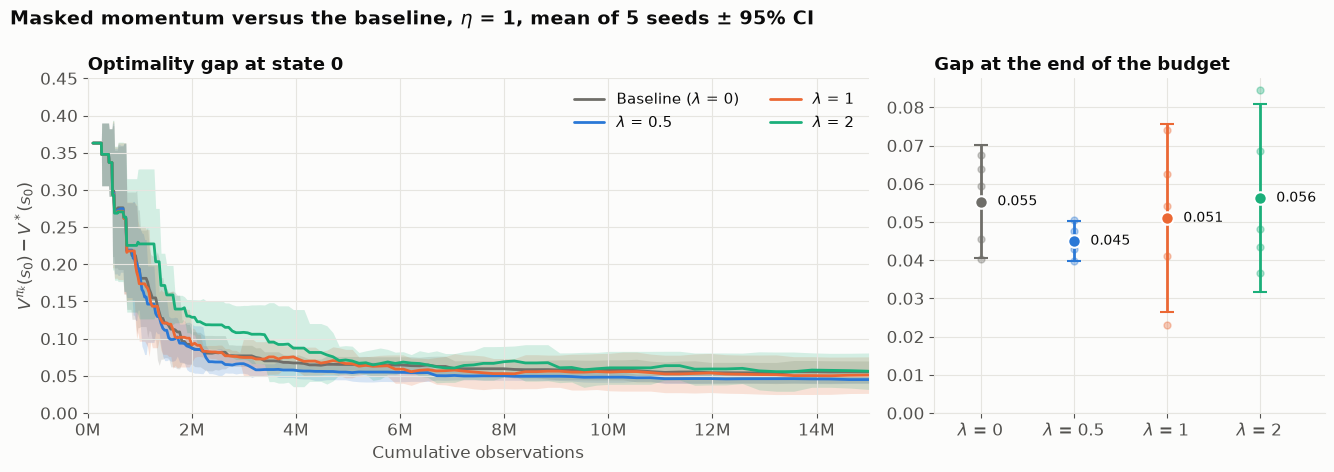

In [18]:
apply_plot_style()
millions = FuncFormatter(lambda x, _: f"{x / 1e6:g}M")
grid_samples = sample_grid(SAMPLE_BUDGET, first=100_000)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"width_ratios": [2, 1]})

ax = axes[0]
for label, (runs, color) in METHODS.items():
    curves = [on_grid(run, grid_samples, gap_at_report_state) for run in runs]
    plot_band(ax, grid_samples, curves, color, label)
ax.set(title="Optimality gap at state 0", xlabel="Cumulative observations",
       ylabel=r"$V^{\pi_k}(s_0) - V^*(s_0)$", xlim=(0, SAMPLE_BUDGET), ylim=(0, 0.45))
ax.xaxis.set_major_formatter(millions)
ax.legend(loc="upper right", ncol=2)

ax = axes[1]
for position, (label, (runs, color)) in enumerate(METHODS.items()):
    gaps = final_gaps[label]
    mean, half_width = mean_ci(gaps[:, None])
    ax.plot(np.full(len(gaps), position), gaps, "o", color=color, alpha=0.35, markersize=5)
    ax.errorbar(position, mean[0], yerr=half_width[0], fmt="o", color=color, markersize=9,
                markeredgecolor="white", markeredgewidth=1.5, capsize=5, elinewidth=2)
    ax.annotate(f"{mean[0]:.3f}", (position, mean[0]), xytext=(12, 0),
                textcoords="offset points", va="center", color=INK, fontsize=10)
ax.set(title="Gap at the end of the budget", xlim=(-0.5, len(METHODS) - 0.3), ylim=(0, None))
ax.set_xticks(range(len(METHODS)), [label.replace("Baseline (", "").rstrip(")") for label in METHODS])
fig.suptitle(f"Masked momentum versus the baseline, $\\eta$ = {ETA:g}, mean of {len(SEEDS)} seeds ± 95% CI",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout()
save_figure(fig, "e2_results")
plt.show()

## 12. Why: momentum with exact Q values, and what the momentum terms add up to

**Control without sampling noise.** Repeat the same update with the *exact*
$Q^{\pi_k}$ of every policy (from the model) instead of the TOMC estimate. If
momentum does not speed up this noise-free version, the reason is the update
rule itself and not the Monte Carlo noise.

**The momentum terms telescope.** With a constant stepsize the KL update gives

$$\log\pi_K(a\mid s)=\log\pi_0(a\mid s)-\eta\sum_{k=0}^{K-1}M_k(s,a)+\text{const}(s),$$
$$\sum_{k=0}^{K-1}M_k=\sum_{k=0}^{K-1}\widehat Q_k+\lambda\,(\widehat Q_{K-1}-\widehat Q_0)$$

for pairs that stay required. The sum of the Q estimates grows with every
update, while all momentum terms together equal one difference of two estimates.
The cell below checks this identity on a saved run, and compares the size of the
two parts and the size of the true change in Q with the sampling noise.

Exact-Q control, eta = 1: optimality gap at state 0 after k updates
     lambda=0  lambda=0.5  lambda=1  lambda=2
k                                            
5     0.11125     0.11310   0.11499   0.11890
10    0.07111     0.07344   0.07582   0.08071
20    0.05102     0.05285   0.05472   0.05862
50    0.02396     0.02466   0.02538   0.02689
100   0.01172     0.01190   0.01208   0.01246


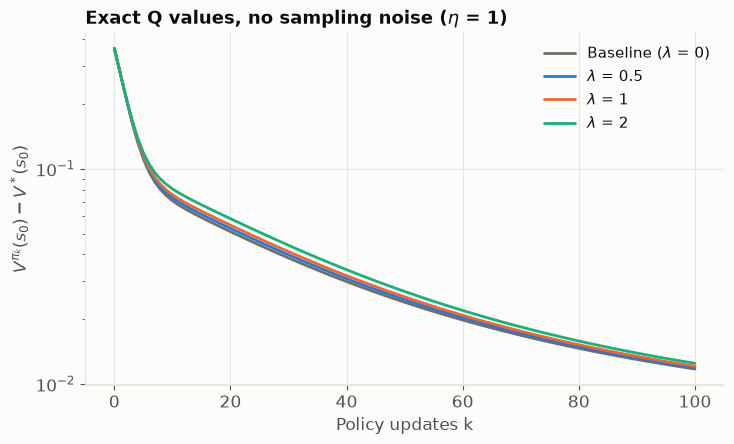

In [19]:
def exact_momentum_pmd(damping, eta, n_updates=100):
    """The same KL update and momentum rule, with exact Q values and no sampling."""
    policy = np.full((N_STATES, N_ACTIONS), 1 / N_ACTIONS)
    all_pairs = np.ones(policy.shape, dtype=bool)
    q_previous, gaps = None, []
    for _ in range(n_updates + 1):
        values = evaluate_policy_bellman(policy, P_exact, c_exact)
        gaps.append(values[REPORT_STATE] - V_STAR[REPORT_STATE])
        q_exact = c_exact[:, None] + GAMMA * (P_exact @ values)
        m_k = momentum_q_table(q_exact, q_previous, all_pairs, damping)
        policy, q_previous = update_policy(policy, m_k, eta), q_exact
    return np.array(gaps)


exact_gaps = {damping: exact_momentum_pmd(damping, ETA) for damping in (0.0,) + LAMBDAS}
checkpoints = (5, 10, 20, 50, 100)
print(f"Exact-Q control, eta = {ETA:g}: optimality gap at state 0 after k updates")
print(pd.DataFrame({f"lambda={damping:g}": gaps[list(checkpoints)]
                    for damping, gaps in exact_gaps.items()},
                   index=pd.Index(checkpoints, name="k")).round(5).to_string())

fig, ax = plt.subplots(figsize=(7.5, 4.6))
for damping, color in zip(exact_gaps, (BASELINE_COLOR,) + SERIES_COLORS):
    ax.plot(exact_gaps[damping], color=color,
            label="Baseline ($\\lambda$ = 0)" if damping == 0 else f"$\\lambda$ = {damping:g}")
ax.set(title=f"Exact Q values, no sampling noise ($\\eta$ = {ETA:g})",
       xlabel="Policy updates k", ylabel=r"$V^{\pi_k}(s_0) - V^*(s_0)$", yscale="log")
ax.yaxis.set_minor_formatter(NullFormatter())
ax.legend()
fig.tight_layout()
save_figure(fig, "e2_exact_control")
plt.show()

In [20]:
def centered(table, mask):
    """Entries of table on mask, minus their state mean (a state shift cancels in the KL update)."""
    counts = np.maximum(mask.sum(axis=1, keepdims=True), 1)
    state_mean = np.where(mask, table, 0.0).sum(axis=1, keepdims=True) / counts
    return (table - state_mean)[mask]


run = results_by_lambda[1.0]
q_hat, masks = run["q_estimates"], run["momentum_masks"]
always_required = run["required_pairs"].all(axis=0)

# 1. Telescoping: all momentum differences of a pair add up to (last Q - first Q).
delta_sum = np.where(masks[1:], q_hat[1:] - q_hat[:-1], 0.0).sum(axis=0)
np.testing.assert_allclose(delta_sum[always_required], (q_hat[-1] - q_hat[0])[always_required],
                           atol=1e-10)

# 2. Size of the two parts of the accumulated exponent, after removing state shifts.
q_part = np.sqrt(np.mean(centered(q_hat.sum(axis=0), always_required) ** 2))
momentum_part = np.sqrt(np.mean(centered(delta_sum, always_required) ** 2))

# 3. Measured difference of consecutive estimates versus the true change in Q.
q_exact = np.array([
    c_exact[:, None] + GAMMA * (P_exact @ evaluate_policy_bellman(pi, P_exact, c_exact))
    for pi in run["evaluated_policies"]
])
measured = np.sqrt(np.mean((q_hat[1:] - q_hat[:-1])[masks[1:]] ** 2))
true_change = np.sqrt(np.mean((q_exact[1:] - q_exact[:-1])[masks[1:]] ** 2))

print(f"lambda = 1, seed {run['seed']}, {len(q_hat)} updates, "
      f"{always_required.sum()} pairs required in every iteration")
print("PASS: the momentum differences of these pairs add up to (last Q estimate - first Q estimate).")
print(f"Accumulated Q estimates (RMS across actions):   {q_part:.3f}")
print(f"All momentum terms together (RMS, lambda = 1):  {momentum_part:.3f}")
print(f"RMS measured difference of consecutive estimates: {measured:.4f}")
print(f"RMS true change of Q between consecutive policies: {true_change:.4f} "
      f"({measured / true_change:.0f} times smaller)")

lambda = 1, seed 0, 29 updates, 290 pairs required in every iteration
PASS: the momentum differences of these pairs add up to (last Q estimate - first Q estimate).
Accumulated Q estimates (RMS across actions):   0.737
All momentum terms together (RMS, lambda = 1):  0.292
RMS measured difference of consecutive estimates: 0.3401
RMS true change of Q between consecutive policies: 0.0344 (10 times smaller)


## 13. State and state–action coverage

For each $\lambda$, first seed. State coverage counts distinct states in the
recorded batch, including its final next state. State–action coverage counts
pairs on which an action was taken. Cumulative coverage is the union across all
batches so far in that run. These are the raw coverage diagnostics.

With this dynamic collection rule, every state has at least one required
action, so state coverage is 100% in every completed batch. Overall state–action
coverage can be lower when some actions fall below the probability threshold.

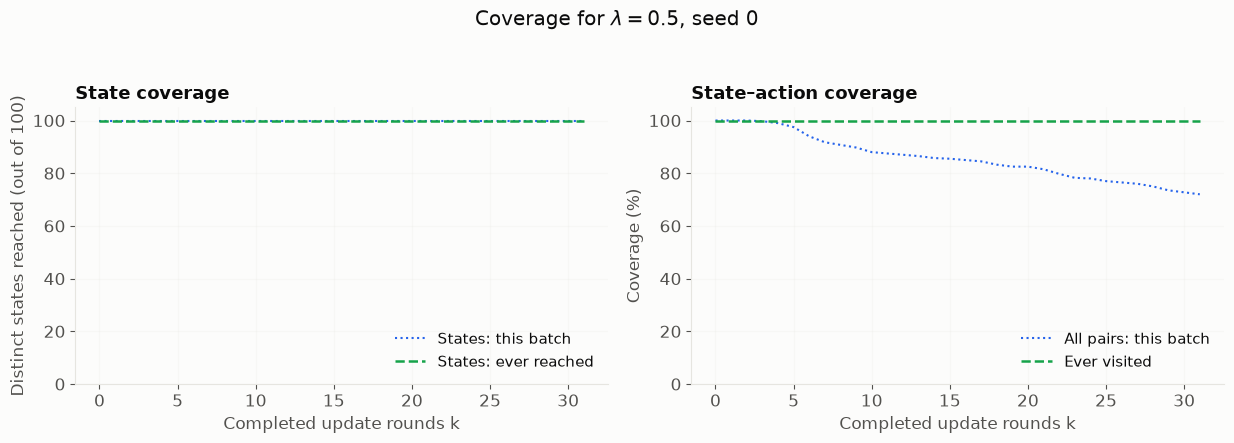

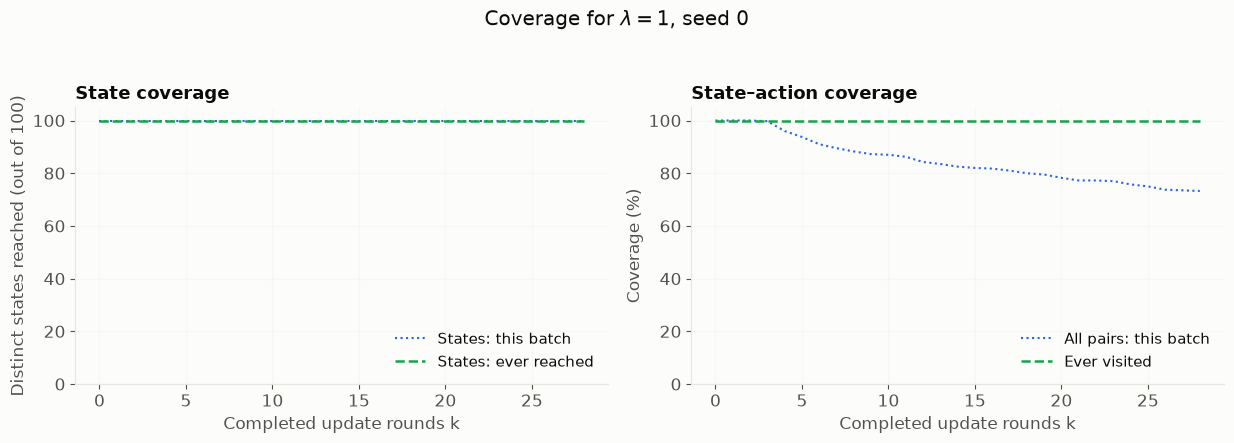

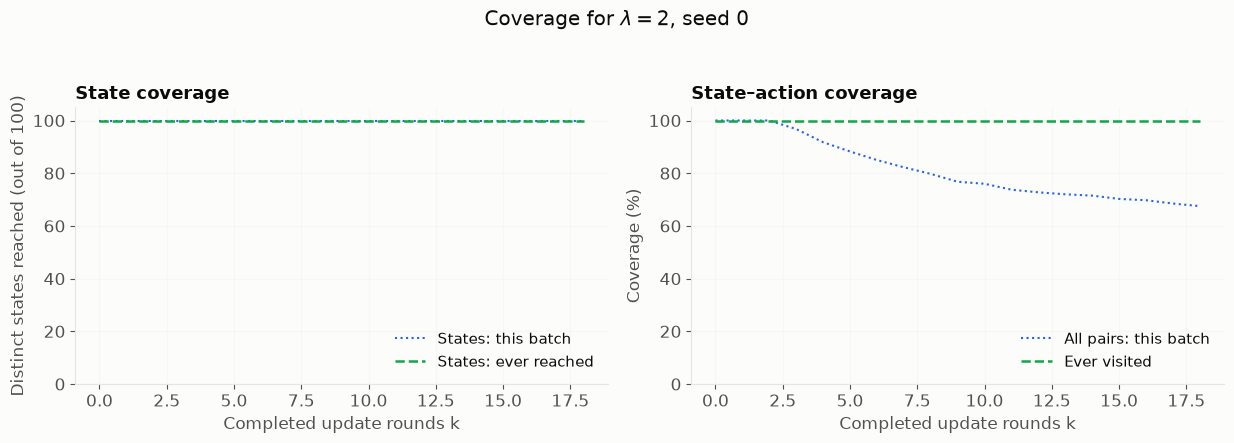

In [21]:
def plot_coverage(damping):
    history = results_by_lambda[damping]["history"]
    k = history["iteration"]
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))

    # Left: number of distinct states reached in the batch and across the run.
    axes[0].plot(k, history["states_visited"], color="#2563eb",
                 linestyle=":", linewidth=1.5, label="States: this batch")
    axes[0].plot(k, history["cumulative_states_visited"], color="#16a34a",
                 linestyle="--", linewidth=1.8, label="States: ever reached")
    axes[0].set(title="State coverage", ylabel=f"Distinct states reached (out of {N_STATES})",
                ylim=(0, N_STATES * 1.05))

    # Right: percentage of state-action pairs visited; each fraction is converted to %.
    axes[1].plot(k, 100 * history["coverage"], color="#2563eb",
                 linestyle=":", linewidth=1.5, label="All pairs: this batch")
    axes[1].plot(k, 100 * history["cumulative_coverage"], color="#16a34a",
                 linestyle="--", linewidth=1.8, label="Ever visited")
    axes[1].set(title="State–action coverage", ylabel="Coverage (%)", ylim=(0, 105))

    # Give both panels the same iteration convention and consistent styling.
    for ax in axes:
        ax.set_xlabel("Completed update rounds k")
        ax.grid(alpha=0.2)
        ax.legend(loc="lower right")
    fig.suptitle(fr"Coverage for $\lambda={damping:g}$, seed {SEEDS[0]}", y=0.98)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()
    return fig, axes


for damping in LAMBDAS:
    plot_coverage(damping)

## 14. Inspect an iteration

Select a run of the first seed, an iteration, and a state to compare the raw Q
estimates against the momentum-adjusted values used for updating.
`available_cost_terms` and `terms_used_in_Q` retain the meaning from the baseline.

In [22]:
# Choose which run, iteration, and state to inspect; this cell does not change training.
lambda_to_inspect = 1.0
result = results_by_lambda[lambda_to_inspect]
history = result["history"]
final_policy = result["policy"]
iteration_to_inspect = 1
state_to_inspect = REPORT_STATE

# Indexing the saved tables leaves one entry per action at the chosen state.
idx = (iteration_to_inspect, state_to_inspect)
first = result["first_visits"][idx]
required = result["required_pairs"][idx]
n = int(history.loc[iteration_to_inspect, "observations"])
# A visit count is different from the number of cost terms used in a first-visit return.
pair_details = pd.DataFrame({
    "action": ACTION_NAMES,
    "policy_probability": result["evaluated_policies"][idx],
    "Q_estimate": result["q_estimates"][idx],
    "M_for_update": result["q_for_update"][idx],
    "required_in_both": result["momentum_masks"][idx],
    "visit_count": result["visits"][idx],
    "first_visit": first,
    "available_cost_terms": np.where(first >= 0, n - first, 0),
    "terms_used_in_Q": np.where(required, n - first, 0),
    "uses_fallback": ~required,
})
print(f"lambda={lambda_to_inspect:g}, iteration {iteration_to_inspect}, state {state_to_inspect}:")
print(pair_details.to_string(index=False))

# Only the final trajectory is retained in full, regardless of the inspected iteration.
states, actions, costs = result["last_batch"]
observations = pd.DataFrame({"state": states[:-1], "action": actions,
                             "cost": costs, "next_state": states[1:]})
print("\nFirst five observations of the final batch:")
print(observations.head().to_string(index=False))

lambda=1, iteration 1, state 0:
action  policy_probability  Q_estimate  M_for_update  required_in_both  visit_count  first_visit  available_cost_terms  terms_used_in_Q  uses_fallback
    up            0.214030    2.372416      2.424339              True        25006           27                556439           556439          False
 right            0.240155    2.294803      2.384282              True        27930            4                556462           556462          False
  down            0.275128    2.238790      2.408209              True        31886            2                556464           556464          False
  left            0.270687    2.214911      2.344179              True        31328            1                556465           556465          False

First five observations of the final batch:
 state  action  cost  next_state
    11       0   0.2           1
     1       3   0.2           0
     0       3   0.2           0
     0       2   0.2          10
   